# Rainbow-DQN with action masking

**Why DQN over PPO here**: our task is essentially a contextual bandit (25 discrete actions, weak temporal deps, Oracle greedy is near-optimal). DQN is structurally better suited:
- Value-based: learns Q(s,a) directly
- Off-policy: reuses replay buffer, sample-efficient
- Native action masking: filter Q-values before argmax

**Components (Rainbow-lite)**:
1. Double DQN (online net selects, target net evaluates)
2. Dueling architecture (V(s) + A(s,a))
3. n-step returns (n=3)
4. Action masking (soft margin around threshold — can violate per-step when aggregate allows)
5. Epsilon-greedy exploration with decay

Goal: match or exceed Oracle (F_AE=0.74) by exploiting aggregate constraint.

## Imports

In [18]:
import os, random, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import gymnasium as gym
from gymnasium import spaces
from qiskit.quantum_info import Operator
from collections import deque

warnings.filterwarnings('ignore')
DEVICE = torch.device("cpu")

## Config

In [19]:
OU_MU       = 0.10
OU_KAPPA    = 0.1
OU_SIGMA    = 0.03
P_MIN       = 0.01
P_MAX       = 0.30
F_THRESHOLD = 0.87
EPISODE_LEN = 50
DENSE_COEF  = 10.0
DET_PENALTY = 30.0
MARGIN_COEF = 3.0
MARGIN_TOL  = 0.01
TEST_EPS    = 50
LIB_PATHS   = {
    "safer":  "evolu_grid_safer_bitflip.pkl",
    "safe":   "evolu_grid_bitflip.pkl",
    "medium": "evolu_grid_medium_bitflip.pkl",
    "agg":    "evolu_grid_hard_bitflip.pkl",
}
N_ACTIONS   = 1 + sum(6 for _ in LIB_PATHS)
OBS_DIM     = 9
HIST_LEN    = 3
WIN_FAB     = 10

HIDDEN_DIM     = 128
Q_LR           = 5e-4
GAMMA          = 0.99
N_STEP         = 3
BATCH_SIZE     = 128
BUFFER_SIZE    = 100_000
TRAIN_STEPS    = 1_000_000
WARMUP_STEPS   = 2_000
TARGET_UPDATE  = 1_000
TRAIN_FREQ     = 4
EPS_START      = 1.0
EPS_END        = 0.02
EPS_DECAY      = 400_000
SOFT_MARGIN    = 0.
EVAL_FREQ      = 5_000
N_EVAL         = 20
TOP_K          = 3

RUN_TAG = "_rainbow_v3"
MASTER_SEED = int(np.random.default_rng().integers(1, 1_000_000))
print(f"Master seed: {MASTER_SEED}")

random.seed(MASTER_SEED); np.random.seed(MASTER_SEED); torch.manual_seed(MASTER_SEED)

Master seed: 379805


## Physics

In [20]:
_I2 = torch.eye(2, dtype=torch.complex64)
_X  = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex64)
_ket0 = torch.tensor([1, 0], dtype=torch.complex64)
_rho_eve = torch.outer(_ket0, _ket0.conj())

_LABELS = {
    '0': torch.tensor([1, 0], dtype=torch.complex64),
    '1': torch.tensor([0, 1], dtype=torch.complex64),
    '+': torch.tensor([1, 1], dtype=torch.complex64) / np.sqrt(2),
    '-': torch.tensor([1, -1], dtype=torch.complex64) / np.sqrt(2),
}

_bb84 = []
for label, psi in _LABELS.items():
    proj = torch.outer(psi, psi.conj())
    rho_clean = torch.kron(proj, _rho_eve)
    rho_flip  = torch.kron(_X @ proj @ _X.conj().T, _rho_eve)
    proj_A = torch.kron(proj, _I2)
    proj_E = torch.kron(_I2, proj)
    _bb84.append((rho_clean, rho_flip, proj_A, proj_E))

def compute_fidelities(U, p):
    f_ab = torch.zeros((), dtype=torch.float32)
    f_ae = torch.zeros((), dtype=torch.float32)
    for rho_clean, rho_flip, proj_A, proj_E in _bb84:
        rho_in  = (1 - p) * rho_clean + p * rho_flip
        rho_out = U @ rho_in @ U.conj().T
        f_ab = f_ab + torch.trace(proj_A @ rho_out).real
        f_ae = f_ae + torch.trace(proj_E @ rho_out).real
    return float(f_ab / 4), float(f_ae / 4)

## Library

In [21]:
grids = {}
for name, path in LIB_PATHS.items():
    with open(path, "rb") as f:
        grids[name] = pickle.load(f)

def _extract_best_U(res):
    best_list, _, _, history_list, _ = res
    loss = np.array([h["best"]["loss"][-1] for h in history_list])
    i = int(np.argmin(loss))
    U = torch.tensor(Operator(best_list[i]).data, dtype=torch.complex64)
    return U, best_list[i]

ps_sorted = sorted(grids["safe"].keys())
Us = {name: [] for name in LIB_PATHS}
for p in ps_sorted:
    for name in LIB_PATHS:
        U, _ = _extract_best_U(grids[name][p])
        Us[name].append(U)

library_U = torch.stack([torch.eye(4, dtype=torch.complex64)] +
                        [u for name in LIB_PATHS for u in Us[name]])
library_labels = ["identity"] + [f"{name}_p{p}" for name in LIB_PATHS for p in ps_sorted]
assert len(library_U) == N_ACTIONS

P_GRID = np.linspace(P_MIN, P_MAX, 100)
fab_table = np.zeros((N_ACTIONS, 100))
fae_table = np.zeros((N_ACTIONS, 100))
for a in range(N_ACTIONS):
    for i, p in enumerate(P_GRID):
        fab_table[a, i], fae_table[a, i] = compute_fidelities(library_U[a], float(p))

def lookup_fidelities(a, p):
    x = (np.clip(p, P_MIN, P_MAX) - P_MIN) / (P_MAX - P_MIN) * 99
    i_lo = int(x); i_hi = min(i_lo + 1, 99); alpha = x - i_lo
    fab = (1 - alpha) * fab_table[a, i_lo] + alpha * fab_table[a, i_hi]
    fae = (1 - alpha) * fae_table[a, i_lo] + alpha * fae_table[a, i_hi]
    return float(fab), float(fae)

def valid_mask_np(p, threshold=F_THRESHOLD, soft_margin=SOFT_MARGIN):
    mask = np.zeros(N_ACTIONS, dtype=bool)
    for a in range(N_ACTIONS):
        fab, _ = lookup_fidelities(a, float(p))
        if fab >= threshold - soft_margin:
            mask[a] = True
    if not mask.any():
        mask[0] = True
    return mask

## Environment

In [22]:
class LibraryEnv(gym.Env):
    def __init__(self, mu=OU_MU, kappa=OU_KAPPA, sigma=OU_SIGMA,
                 p_min=P_MIN, p_max=P_MAX, episode_len=EPISODE_LEN,
                 f_threshold=F_THRESHOLD, dense_coef=DENSE_COEF, det_penalty=DET_PENALTY,
                 margin_coef=MARGIN_COEF, margin_tol=MARGIN_TOL):
        super().__init__()
        self.mu = mu; self.kappa = kappa; self.sigma = sigma
        self.p_min = p_min; self.p_max = p_max
        self.episode_len = episode_len
        self.f_threshold = f_threshold
        self.dense_coef = dense_coef; self.det_penalty = det_penalty
        self.margin_coef = margin_coef; self.margin_tol = margin_tol
        self.action_space = spaces.Discrete(N_ACTIONS)
        self.observation_space = spaces.Box(
            low=np.float32(-2.0), high=np.float32(2.0),
            shape=(OBS_DIM,), dtype=np.float32)

    def _obs(self):
        recent = self.f_ab_ep[-WIN_FAB:] if self.f_ab_ep else [1.0]
        sum_fab = sum(self.f_ab_ep)
        safety_budget = self.f_threshold * self.episode_len - sum_fab
        return np.array([
            self.p,
            self.p_hist[-1] if len(self.p_hist) >= 1 else self.p,
            self.p_hist[-2] if len(self.p_hist) >= 2 else self.p,
            self.p_hist[-3] if len(self.p_hist) >= 3 else self.p,
            self.last_action / (N_ACTIONS - 1),
            float(np.mean(recent)),
            float(np.mean(self.f_ae_ep)) if self.f_ae_ep else 0.5,
            (self.episode_len - self.t) / self.episode_len,
            safety_budget / self.episode_len,
        ], dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.p = float(self.mu + self.sigma * self.np_random.standard_normal())
        self.p = float(np.clip(self.p, self.p_min, self.p_max))
        self.p_hist = []; self.last_action = 0
        self.f_ab_ep = []; self.f_ae_ep = []; self.t = 0
        return self._obs(), {}

    def step(self, action):
        U = library_U[int(action)]
        f_ab, f_ae = compute_fidelities(U, self.p)
        self.p_hist.append(self.p)
        if len(self.p_hist) > HIST_LEN:
            self.p_hist.pop(0)
        self.last_action = int(action)
        self.f_ab_ep.append(f_ab); self.f_ae_ep.append(f_ae); self.t += 1
        reward = f_ae - 0.5
        running_fab = float(np.mean(self.f_ab_ep))
        if running_fab < self.f_threshold:
            reward -= self.dense_coef * (self.f_threshold - running_fab)
        else:
            excess = running_fab - self.f_threshold
            if excess > self.margin_tol:
                reward -= self.margin_coef * (excess - self.margin_tol)
        done = self.t >= self.episode_len
        if done and running_fab < self.f_threshold:
            reward -= self.det_penalty
        decay = np.exp(-self.kappa)
        noise_std = self.sigma * np.sqrt((1 - np.exp(-2 * self.kappa)) / (2 * self.kappa))
        self.p = self.mu + (self.p - self.mu) * decay + noise_std * self.np_random.standard_normal()
        self.p = float(np.clip(self.p, self.p_min, self.p_max))
        return self._obs(), float(reward), done, False, {"f_ab": f_ab, "f_ae": f_ae, "p": self.p}

## Dueling Q-Network

In [23]:
class DuelingQNet(nn.Module):
    def __init__(self, obs_dim=OBS_DIM, n_actions=N_ACTIONS, hidden=HIDDEN_DIM):
        super().__init__()
        self.feat = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU())
        self.value_head = nn.Linear(hidden, 1)
        self.adv_head = nn.Linear(hidden, n_actions)
    def forward(self, obs):
        z = self.feat(obs)
        v = self.value_head(z)
        adv = self.adv_head(z)
        return v + adv - adv.mean(dim=-1, keepdim=True)
    def act(self, obs_np, mask_np, epsilon=0.0):
        if np.random.random() < epsilon:
            valid = np.where(mask_np)[0]
            return int(np.random.choice(valid))
        with torch.no_grad():
            obs = torch.tensor(obs_np, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            mask = torch.tensor(mask_np, dtype=torch.bool, device=DEVICE).unsqueeze(0)
            q = self.forward(obs)
            q = q.masked_fill(~mask, -1e9)
            return int(q.argmax(dim=-1).item())

## Replay buffer with n-step returns

In [24]:
class ReplayBuffer:
    def __init__(self, capacity=BUFFER_SIZE, obs_dim=OBS_DIM, n_actions=N_ACTIONS, n_step=N_STEP, gamma=GAMMA):
        self.capacity = capacity
        self.obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.acts = np.zeros(capacity, dtype=np.int64)
        self.rews = np.zeros(capacity, dtype=np.float32)
        self.dones = np.zeros(capacity, dtype=np.float32)
        self.masks = np.zeros((capacity, n_actions), dtype=bool)
        self.next_masks = np.zeros((capacity, n_actions), dtype=bool)
        self.size = 0; self.idx = 0
        self.n_step = n_step; self.gamma = gamma
        self.nstep_queue = deque(maxlen=n_step)

    def _store(self, obs, act, rew, next_obs, done, mask, next_mask):
        i = self.idx
        self.obs[i] = obs; self.acts[i] = act; self.rews[i] = rew
        self.next_obs[i] = next_obs; self.dones[i] = float(done)
        self.masks[i] = mask; self.next_masks[i] = next_mask
        self.idx = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def add(self, obs, act, rew, next_obs, done, mask, next_mask):
        self.nstep_queue.append((obs, act, rew, next_obs, done, mask, next_mask))
        if len(self.nstep_queue) == self.n_step:
            o0, a0, _, _, _, m0, _ = self.nstep_queue[0]
            R = 0.0; d = False; last_next_obs = next_obs; last_next_mask = next_mask
            for k, tr in enumerate(self.nstep_queue):
                _, _, r_k, no_k, d_k, _, nm_k = tr
                R += (self.gamma ** k) * r_k
                last_next_obs = no_k; last_next_mask = nm_k
                if d_k:
                    d = True; break
            self._store(o0, a0, R, last_next_obs, d, m0, last_next_mask)
        if done:
            while len(self.nstep_queue) > 1:
                self.nstep_queue.popleft()
                o0, a0, _, _, _, m0, _ = self.nstep_queue[0]
                R = 0.0; d = True; last_next_obs = next_obs; last_next_mask = next_mask
                for k, tr in enumerate(self.nstep_queue):
                    _, _, r_k, no_k, d_k, _, nm_k = tr
                    R += (self.gamma ** k) * r_k
                    last_next_obs = no_k; last_next_mask = nm_k
                self._store(o0, a0, R, last_next_obs, d, m0, last_next_mask)
            self.nstep_queue.clear()

    def sample(self, batch_size):
        idx = np.random.randint(0, self.size, size=batch_size)
        return (torch.tensor(self.obs[idx]), torch.tensor(self.acts[idx]),
                torch.tensor(self.rews[idx]), torch.tensor(self.next_obs[idx]),
                torch.tensor(self.dones[idx]), torch.tensor(self.masks[idx]),
                torch.tensor(self.next_masks[idx]))

## Training loop

In [25]:
q_online = DuelingQNet().to(DEVICE)
q_target = DuelingQNet().to(DEVICE)
q_target.load_state_dict(q_online.state_dict())
q_target.eval()
opt = torch.optim.Adam(q_online.parameters(), lr=Q_LR)
buffer = ReplayBuffer()
env = LibraryEnv()

def train_step():
    if buffer.size < BATCH_SIZE:
        return 0.0
    obs, acts, rews, next_obs, dones, masks, next_masks = buffer.sample(BATCH_SIZE)
    obs = obs.to(DEVICE); next_obs = next_obs.to(DEVICE)
    acts = acts.to(DEVICE); rews = rews.to(DEVICE); dones = dones.to(DEVICE)
    masks = masks.to(DEVICE); next_masks = next_masks.to(DEVICE)
    q_pred = q_online(obs).gather(1, acts.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        q_next_online = q_online(next_obs)
        q_next_online = q_next_online.masked_fill(~next_masks, -1e9)
        next_acts = q_next_online.argmax(dim=-1)
        q_next_target = q_target(next_obs).gather(1, next_acts.unsqueeze(1)).squeeze(1)
        q_target_val = rews + (GAMMA ** N_STEP) * (1 - dones) * q_next_target
    loss = F.smooth_l1_loss(q_pred, q_target_val)
    opt.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(q_online.parameters(), 10.0)
    opt.step()
    return float(loss.item())

In [26]:
def eval_agent(n_eval=N_EVAL, seed_base=10_000_000 + MASTER_SEED):
    faes, fabs, dets = [], [], 0
    eval_env = LibraryEnv()
    for ep in range(n_eval):
        obs, _ = eval_env.reset(seed=(seed_base + ep) % (2**31 - 1))
        done = False
        while not done:
            mask = valid_mask_np(obs[0])
            a = q_online.act(obs, mask, epsilon=0.0)
            obs, _, done, _, _ = eval_env.step(a)
        faes.append(np.mean(eval_env.f_ae_ep))
        fabs.append(np.mean(eval_env.f_ab_ep))
        if np.mean(eval_env.f_ab_ep) < F_THRESHOLD:
            dets += 1
    return float(np.mean(faes)), float(np.mean(fabs)), dets / n_eval

history = []
top_k = []
best_score = -np.inf; best_step = 0

obs, _ = env.reset(seed=MASTER_SEED)
mask = valid_mask_np(obs[0])
step = 0; ep_return = 0.0; n_eps = 0

print(f"Starting training: {TRAIN_STEPS} steps (warmup {WARMUP_STEPS})")

while step < TRAIN_STEPS:
    epsilon = max(EPS_END, EPS_START - (EPS_START - EPS_END) * step / EPS_DECAY)
    if step < WARMUP_STEPS:
        valid = np.where(mask)[0]
        a = int(np.random.choice(valid))
    else:
        a = q_online.act(obs, mask, epsilon=epsilon)
    next_obs, reward, done, _, _ = env.step(a)
    next_mask = valid_mask_np(next_obs[0])
    buffer.add(obs, a, reward, next_obs, done, mask, next_mask)
    ep_return += reward; step += 1
    obs = next_obs; mask = next_mask
    if done:
        obs, _ = env.reset(seed=MASTER_SEED + n_eps + 1)
        mask = valid_mask_np(obs[0])
        n_eps += 1; ep_return = 0.0
    if step >= WARMUP_STEPS and step % TRAIN_FREQ == 0:
        loss = train_step()
    if step % TARGET_UPDATE == 0:
        q_target.load_state_dict(q_online.state_dict())
    if step % EVAL_FREQ == 0 and step >= WARMUP_STEPS:
        mfae, mfab, drate = eval_agent()
        score = mfae - 2.0 * drate
        history.append({"step": step, "f_ae": mfae, "f_ab": mfab, "det": drate,
                        "score": score, "epsilon": epsilon})
        state = {"q_online": q_online.state_dict(), "q_target": q_target.state_dict()}
        if len(top_k) < TOP_K or score > min(s for s, _, _ in top_k):
            path = f"rainbow_best{RUN_TAG}_top{step}"
            torch.save(state, f"{path}.pt")
            top_k.append((score, step, path))
            top_k.sort(reverse=True)
            if len(top_k) > TOP_K:
                _, _, drop_path = top_k.pop()
                try:
                    os.remove(f"{drop_path}.pt")
                except Exception:
                    pass
        if score > best_score:
            best_score = score; best_step = step
            torch.save(state, f"rainbow_best{RUN_TAG}.pt")
        print(f"  [Step {step:6d}] F_AE={mfae:.4f}  F_AB={mfab:.4f}  det={drate*100:.1f}%  "
              f"score={score:.4f}  eps={epsilon:.3f}")

print(f"\nBest: step={best_step}, score={best_score:.4f}")
print(f"Top-{TOP_K} checkpoints:")
for s, stp, path in top_k:
    print(f"  score={s:.4f}  step={stp}  path={path}.pt")

Starting training: 1000000 steps (warmup 2000)
  [Step   5000] F_AE=0.7457  F_AB=0.8789  det=0.0%  score=0.7457  eps=0.988
  [Step  10000] F_AE=0.7459  F_AB=0.8784  det=0.0%  score=0.7459  eps=0.976
  [Step  15000] F_AE=0.7476  F_AB=0.8778  det=0.0%  score=0.7476  eps=0.963
  [Step  20000] F_AE=0.7430  F_AB=0.8812  det=0.0%  score=0.7430  eps=0.951
  [Step  25000] F_AE=0.7463  F_AB=0.8783  det=0.0%  score=0.7463  eps=0.939
  [Step  30000] F_AE=0.7478  F_AB=0.8776  det=0.0%  score=0.7478  eps=0.927
  [Step  35000] F_AE=0.7449  F_AB=0.8795  det=0.0%  score=0.7449  eps=0.914
  [Step  40000] F_AE=0.7445  F_AB=0.8797  det=0.0%  score=0.7445  eps=0.902
  [Step  45000] F_AE=0.7472  F_AB=0.8781  det=0.0%  score=0.7472  eps=0.890
  [Step  50000] F_AE=0.7467  F_AB=0.8787  det=0.0%  score=0.7467  eps=0.878
  [Step  55000] F_AE=0.7462  F_AB=0.8789  det=0.0%  score=0.7462  eps=0.865
  [Step  60000] F_AE=0.7472  F_AB=0.8785  det=0.0%  score=0.7472  eps=0.853
  [Step  65000] F_AE=0.7485  F_AB=0.8777 

## Evaluation

In [27]:
def make_rainbow_policy(q_net):
    def policy(obs, env):
        mask = valid_mask_np(obs[0])
        return q_net.act(obs, mask, epsilon=0.0)
    return policy

SAFER_OFFSET = 1
def static_safe_policy(obs, env):
    p = obs[0]
    return SAFER_OFFSET + int(np.argmin([abs(pl - p) for pl in ps_sorted]))
def identity_policy(obs, env):
    return 0
def oracle_policy(obs, env):
    p = obs[0]
    best_a, best_fae = 0, -np.inf
    for a in range(N_ACTIONS):
        f_ab, f_ae = lookup_fidelities(a, float(p))
        if f_ab >= env.f_threshold and f_ae > best_fae:
            best_fae = f_ae; best_a = a
    return best_a

POLICIES = {}
for rank, (train_score, stp, path) in enumerate(top_k, 1):
    q_net = DuelingQNet().to(DEVICE)
    q_net.load_state_dict(torch.load(f"{path}.pt", map_location=DEVICE)["q_online"])
    q_net.eval()
    POLICIES[f"Rainbow top-{rank} (step {stp})"] = make_rainbow_policy(q_net)

POLICIES["Static safe"] = static_safe_policy
POLICIES["Oracle"]      = oracle_policy
POLICIES["Identity"]    = identity_policy

def run_episode(policy_fn, env_seed):
    e = LibraryEnv()
    obs, _ = e.reset(seed=env_seed)
    done = False; actions = []
    while not done:
        a = policy_fn(obs, e); actions.append(a)
        obs, _, done, _, _ = e.step(a)
    return np.mean(e.f_ae_ep), np.mean(e.f_ab_ep), actions

TEST_SEED_BASE = (MASTER_SEED + 1_000_000_000) % (2**31 - 1)
results = {name: {"f_ae": [], "f_ab": [], "det": 0, "actions": []} for name in POLICIES}
for name, pol in POLICIES.items():
    print(f"Eval {name}...")
    for ep in range(TEST_EPS):
        seed = (TEST_SEED_BASE + ep) % (2**31 - 1)
        fae, fab, actions = run_episode(pol, env_seed=int(seed))
        results[name]["f_ae"].append(fae)
        results[name]["f_ab"].append(fab)
        results[name]["actions"].extend(actions)
        if fab < F_THRESHOLD:
            results[name]["det"] += 1

rows = []
for name, r in results.items():
    rows.append({
        "Method":    name,
        "Mean F_AE": f"{np.mean(r['f_ae']):.4f}",
        "Std F_AE":  f"{np.std(r['f_ae']):.4f}",
        "Mean F_AB": f"{np.mean(r['f_ab']):.4f}",
        "Det. rate": f"{r['det'] / TEST_EPS * 100:.1f}%",
    })
pd.DataFrame(rows).set_index("Method")

Eval Rainbow top-1 (step 185000)...
Eval Rainbow top-2 (step 190000)...
Eval Rainbow top-3 (step 440000)...
Eval Static safe...
Eval Oracle...
Eval Identity...


,Mean F_AE,Std F_AE,Mean F_AB,Det. rate
Method,,,,
Rainbow top-1 (step 185000),0.7434,0.0291,0.8755,0.0%
Rainbow top-2 (step 190000),0.7433,0.0291,0.8755,0.0%
Rainbow top-3 (step 440000),0.7432,0.0290,0.8756,0.0%
Static safe,0.7199,0.0269,0.8900,0.0%
Oracle,0.7434,0.0291,0.8755,0.0%
Identity,0.5000,0.0000,0.9478,0.0%


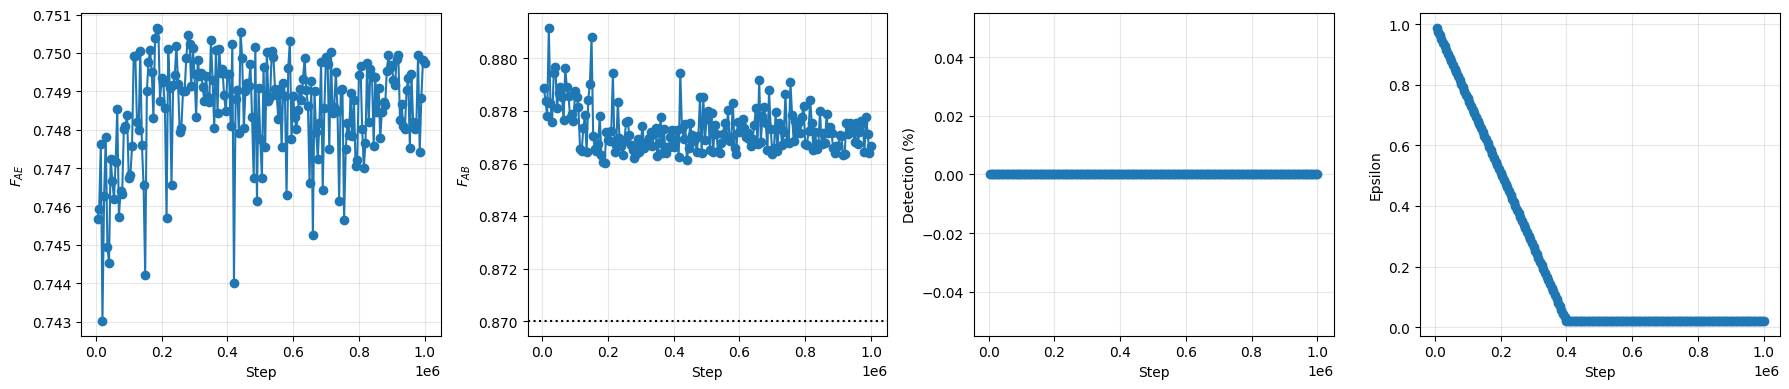

In [28]:
hist_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].plot(hist_df["step"], hist_df["f_ae"], "o-")
axes[0].set_xlabel("Step"); axes[0].set_ylabel("$F_{AE}$"); axes[0].grid(alpha=0.3)
axes[1].plot(hist_df["step"], hist_df["f_ab"], "o-")
axes[1].axhline(F_THRESHOLD, color="k", ls=":")
axes[1].set_xlabel("Step"); axes[1].set_ylabel("$F_{AB}$"); axes[1].grid(alpha=0.3)
axes[2].plot(hist_df["step"], hist_df["det"] * 100, "o-")
axes[2].set_xlabel("Step"); axes[2].set_ylabel("Detection (%)"); axes[2].grid(alpha=0.3)
axes[3].plot(hist_df["step"], hist_df["epsilon"], "o-")
axes[3].set_xlabel("Step"); axes[3].set_ylabel("Epsilon"); axes[3].grid(alpha=0.3)
plt.tight_layout(); plt.show()

with open(f"exp7_results{RUN_TAG}.pkl", "wb") as f:
    pickle.dump({"results": results, "history": history, "master_seed": MASTER_SEED}, f)

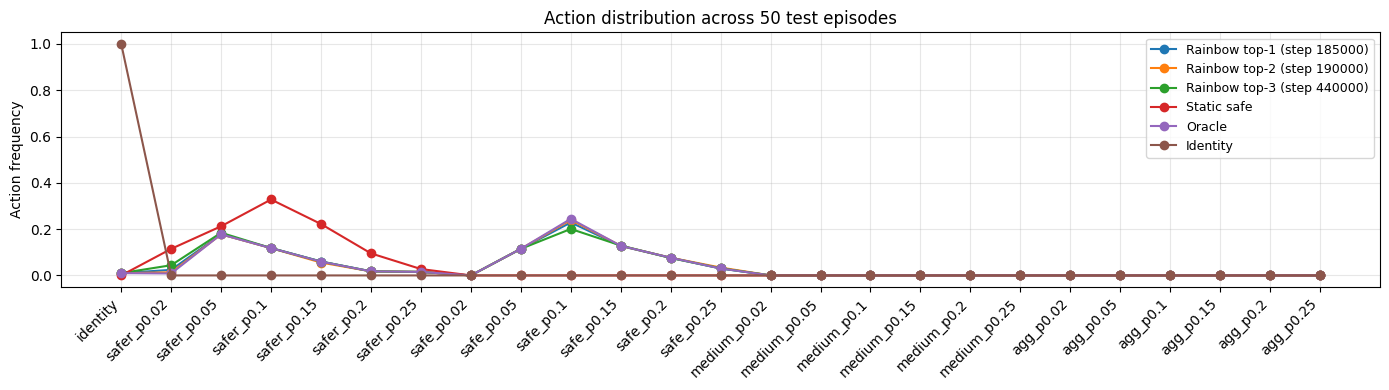

In [29]:
fig, ax = plt.subplots(figsize=(14, 4))
for name, r in results.items():
    counts = np.bincount(r["actions"], minlength=N_ACTIONS)
    ax.plot(range(N_ACTIONS), counts / counts.sum(), "o-", label=name)
ax.set_xticks(range(N_ACTIONS))
ax.set_xticklabels(library_labels, rotation=45, ha="right")
ax.set_ylabel("Action frequency")
ax.set_title(f"Action distribution across {TEST_EPS} test episodes")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:
categories = {
    "identity": [0],
    "safer":    list(range(1, 7)),
    "safe":     list(range(7, 13)),
    "medium":   list(range(13, 19)),
    "agg":      list(range(19, 25)),
}
rows = []
for name, r in results.items():
    counts = np.bincount(r["actions"], minlength=N_ACTIONS)
    total = counts.sum()
    row = {"Method": name}
    for cat, idx in categories.items():
        row[cat] = f"{100 * counts[idx].sum() / total:.1f}%"
    rows.append(row)
pd.DataFrame(rows).set_index("Method")


,identity,safer,safe,medium,agg
Method,,,,,
Rainbow top-1 (step 185000),1.0%,41.3%,57.7%,0.0%,0.0%
Rainbow top-2 (step 190000),1.0%,39.7%,59.3%,0.0%,0.0%
Rainbow top-3 (step 440000),1.0%,43.9%,55.1%,0.0%,0.0%
Static safe,0.0%,100.0%,0.0%,0.0%,0.0%
Oracle,1.0%,39.6%,59.4%,0.0%,0.0%
Identity,100.0%,0.0%,0.0%,0.0%,0.0%


In [31]:
p_bins = [(0.00, 0.05), (0.05, 0.10), (0.10, 0.15), (0.15, 0.20), (0.20, 0.25), (0.25, 0.30)]
p_centers = [(lo + hi) / 2 for lo, hi in p_bins]

def analyze_per_p(policy_fn, n_eps=50, seed_base=TEST_SEED_BASE):
    records = []
    for ep in range(n_eps):
        e = LibraryEnv()
        obs, _ = e.reset(seed=(seed_base + ep) % (2**31 - 1))
        done = False
        while not done:
            p_current = float(obs[0])
            a = policy_fn(obs, e)
            records.append((p_current, a))
            obs, _, done, _, _ = e.step(a)
    return records

for name, pol in POLICIES.items():
    print(f"\n=== {name} ===")
    records = analyze_per_p(pol)
    for lo, hi in p_bins:
        actions_in_bin = [a for p, a in records if lo <= p < hi]
        if not actions_in_bin:
            continue
        unique, counts = np.unique(actions_in_bin, return_counts=True)
        n_total = len(actions_in_bin)
        sorted_idx = np.argsort(-counts)
        top3 = [(library_labels[int(unique[i])], counts[i] / n_total * 100)
                for i in sorted_idx[:3]]
        top3_str = "  ".join([f"{lbl}({pct:.0f}%)" for lbl, pct in top3])
        print(f"  p∈[{lo:.2f},{hi:.2f}]  n={n_total:4d}  →  {top3_str}")



=== Rainbow top-1 (step 185000) ===
  p∈[0.00,0.05]  n= 453  →  safe_p0.05(63%)  safe_p0.1(34%)  safer_p0.02(3%)
  p∈[0.05,0.10]  n= 801  →  safe_p0.1(52%)  safer_p0.05(42%)  safer_p0.02(6%)
  p∈[0.10,0.15]  n= 701  →  safe_p0.15(45%)  safer_p0.1(39%)  safer_p0.05(16%)
  p∈[0.15,0.20]  n= 398  →  safe_p0.2(48%)  safer_p0.15(38%)  safe_p0.25(9%)
  p∈[0.20,0.25]  n= 126  →  safer_p0.2(35%)  safe_p0.25(32%)  safer_p0.25(30%)
  p∈[0.25,0.30]  n=  21  →  identity(100%)

=== Rainbow top-2 (step 190000) ===
  p∈[0.00,0.05]  n= 453  →  safe_p0.05(63%)  safe_p0.1(36%)  safer_p0.02(0%)
  p∈[0.05,0.10]  n= 801  →  safe_p0.1(54%)  safer_p0.05(42%)  safer_p0.02(4%)
  p∈[0.10,0.15]  n= 701  →  safe_p0.15(46%)  safer_p0.1(39%)  safer_p0.05(16%)
  p∈[0.15,0.20]  n= 398  →  safe_p0.2(48%)  safer_p0.15(35%)  safe_p0.25(11%)
  p∈[0.20,0.25]  n= 126  →  safer_p0.2(35%)  safe_p0.25(32%)  safer_p0.25(30%)
  p∈[0.25,0.30]  n=  21  →  identity(100%)

=== Rainbow top-3 (step 440000) ===
  p∈[0.00,0.05]  n= 45

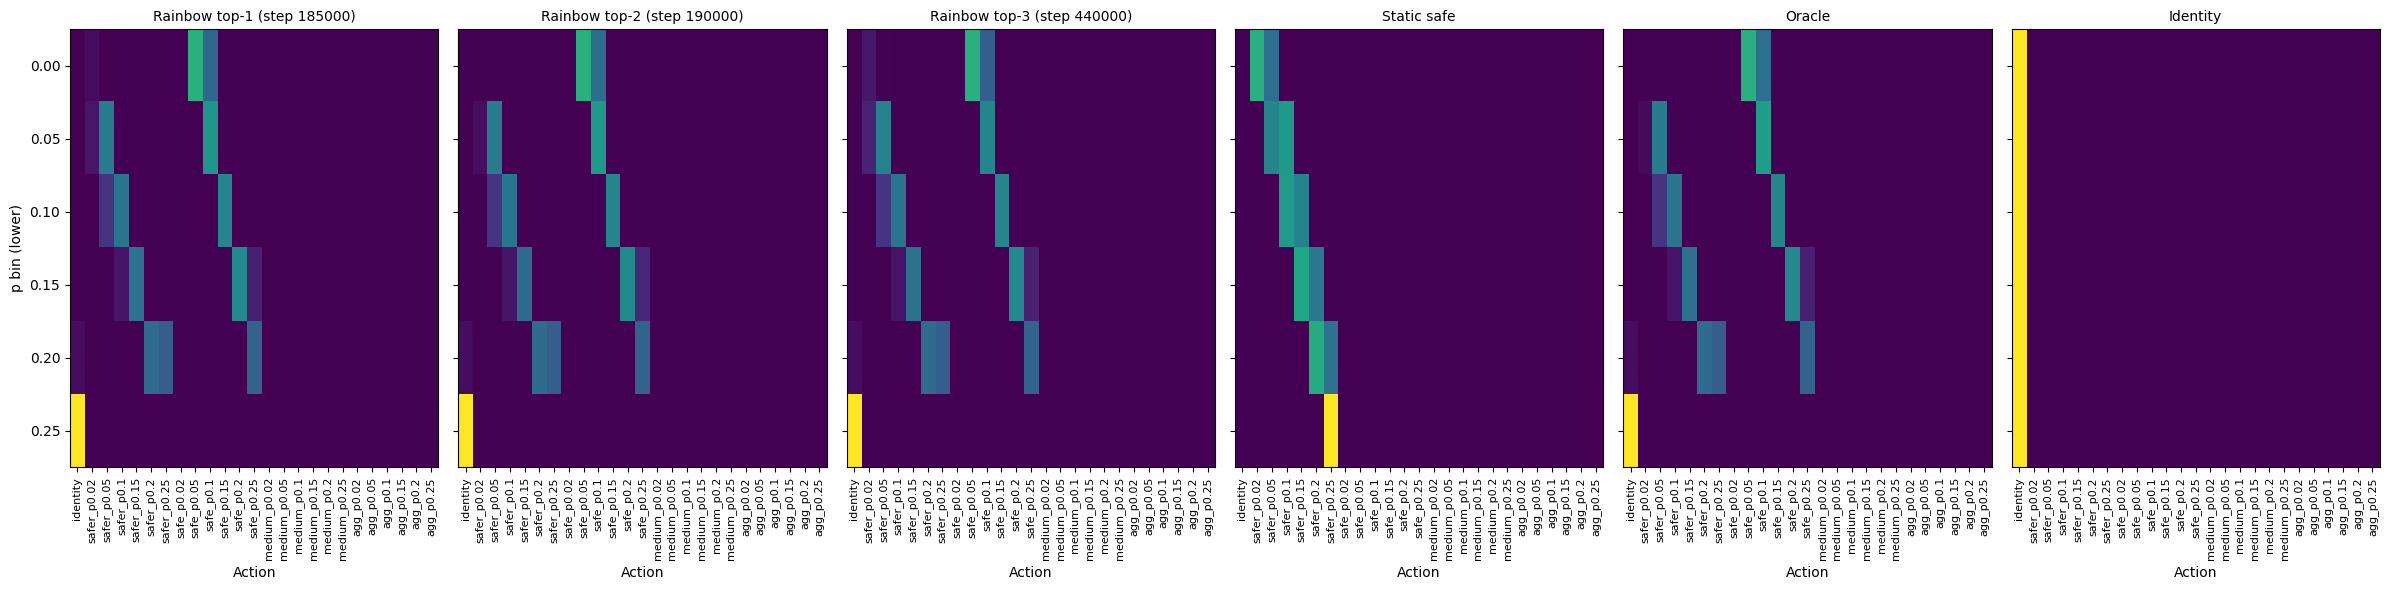

In [32]:
fig, axes = plt.subplots(1, len(POLICIES), figsize=(4 * len(POLICIES), 6), sharey=True)
for ax, (name, pol) in zip(axes, POLICIES.items()):
    records = analyze_per_p(pol)
    mat = np.zeros((len(p_bins), N_ACTIONS))
    for p, a in records:
        for i, (lo, hi) in enumerate(p_bins):
            if lo <= p < hi:
                mat[i, a] += 1
                break
    mat = mat / (mat.sum(axis=1, keepdims=True) + 1e-9)
    ax.imshow(mat, aspect="auto", cmap="viridis")
    ax.set_xticks(range(N_ACTIONS))
    ax.set_xticklabels(library_labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(p_bins)))
    ax.set_yticklabels([f"{lo:.2f}" for lo, _ in p_bins])
    ax.set_xlabel("Action")
    if ax is axes[0]:
        ax.set_ylabel("p bin (lower)")
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()
